# Sentinel-1 LULC prototype — Mannheim

**Input:** latitude, longitude and a start month. **Output:** 12 monthly LULC maps (9 Dynamic World classes),
the percentage of each class per month, the month-to-month change and the total change (percentage points),
and an independent sanity check against ESA WorldCover 2021.

**Location:** Mannheim city centre (inside the Heidelberg–Rhine-Neckar training area).

**How to use:** set the parameters in the next cell, then *Run → Run All Cells*. All tables and figures below are
computed from the run in this notebook (`result`), so they always belong to the location and model set here.

In [1]:
# ============================ PARAMETERS ============================
CITY = "Mannheim"
LAT = 49.4875              # latitude  (decimal degrees)
LON = 8.466              # longitude (decimal degrees)
START_MONTH = "2025-01"  # first of the 12 months, YYYY-MM

SIZE_KM = 10             # side length of the square area (km)
GEE_PROJECT = "heidelberg-lulc-research"   # your Google Cloud project registered for Earth Engine
WEIGHTS = "model/best_model.pt"            # trained model (SegFormer, 10 m, Sentinel-1 only)
INPUT_RES = 10           # 10 = native 10 m input; 40 = 4x4 aggregated input (needs a 40 m or mixed model)
# ====================================================================

In [2]:
import os, site, sys, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
_pylibs = "/home/jovyan/vault/heidelberg_lulc_2025/pylibs/lib/python3.11/site-packages"
if os.path.isdir(_pylibs):                  # SRH Data Lab: packages installed in the persistent vault
    site.addsitedir(_pylibs)
sys.path.insert(0, os.getcwd())

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display
import lulc_prototype as P

pd.set_option("display.width", 200)
FIG = os.path.abspath(os.path.join("..", "outputs", "figures"))   # report figures
os.makedirs(FIG, exist_ok=True)
print("weights found:", os.path.exists(WEIGHTS))

weights found: True


In [3]:
import ee
ee.Initialize(project=GEE_PROJECT)
print("Earth Engine OK:", ee.Number(1).add(1).getInfo())

Earth Engine OK: 2


In [4]:
result = P.run(LAT, LON, START_MONTH, WEIGHTS, GEE_PROJECT, size_km=SIZE_KM, out_dir="results",
               input_res=INPUT_RES)
plt.close("all")

15:35:45 AOI 10.00 km x 10.00 km around (49.4875, 8.466), EPSG:32632, 1000x1000 px | months 2025-01 … 2025-12


15:35:47 ascending relative orbits found (scenes): {15: 53} -> using orbit 15


15:35:57 model segformer / mit_b2 (trained at 10 m) on cuda; input resolution 10 m (1000x1000 px)


15:36:06   2025-01: 3 scene(s), valid 100.0 %, mapped


15:36:09   2025-02: 2 scene(s), valid 100.0 %, mapped


15:36:13   2025-03: 3 scene(s), valid 100.0 %, mapped


... (7 outputs left out)

15:36:54   2025-11: 5 scene(s), valid 100.0 %, mapped


15:36:58   2025-12: 6 scene(s), valid 100.0 %, mapped


15:37:03 WorldCover check: pixel agreement 69.2 %


15:37:03 done in 1.3 min -> results/lat49.4875_lon8.4660_2025-01


## 1. LULC maps over the 12 months

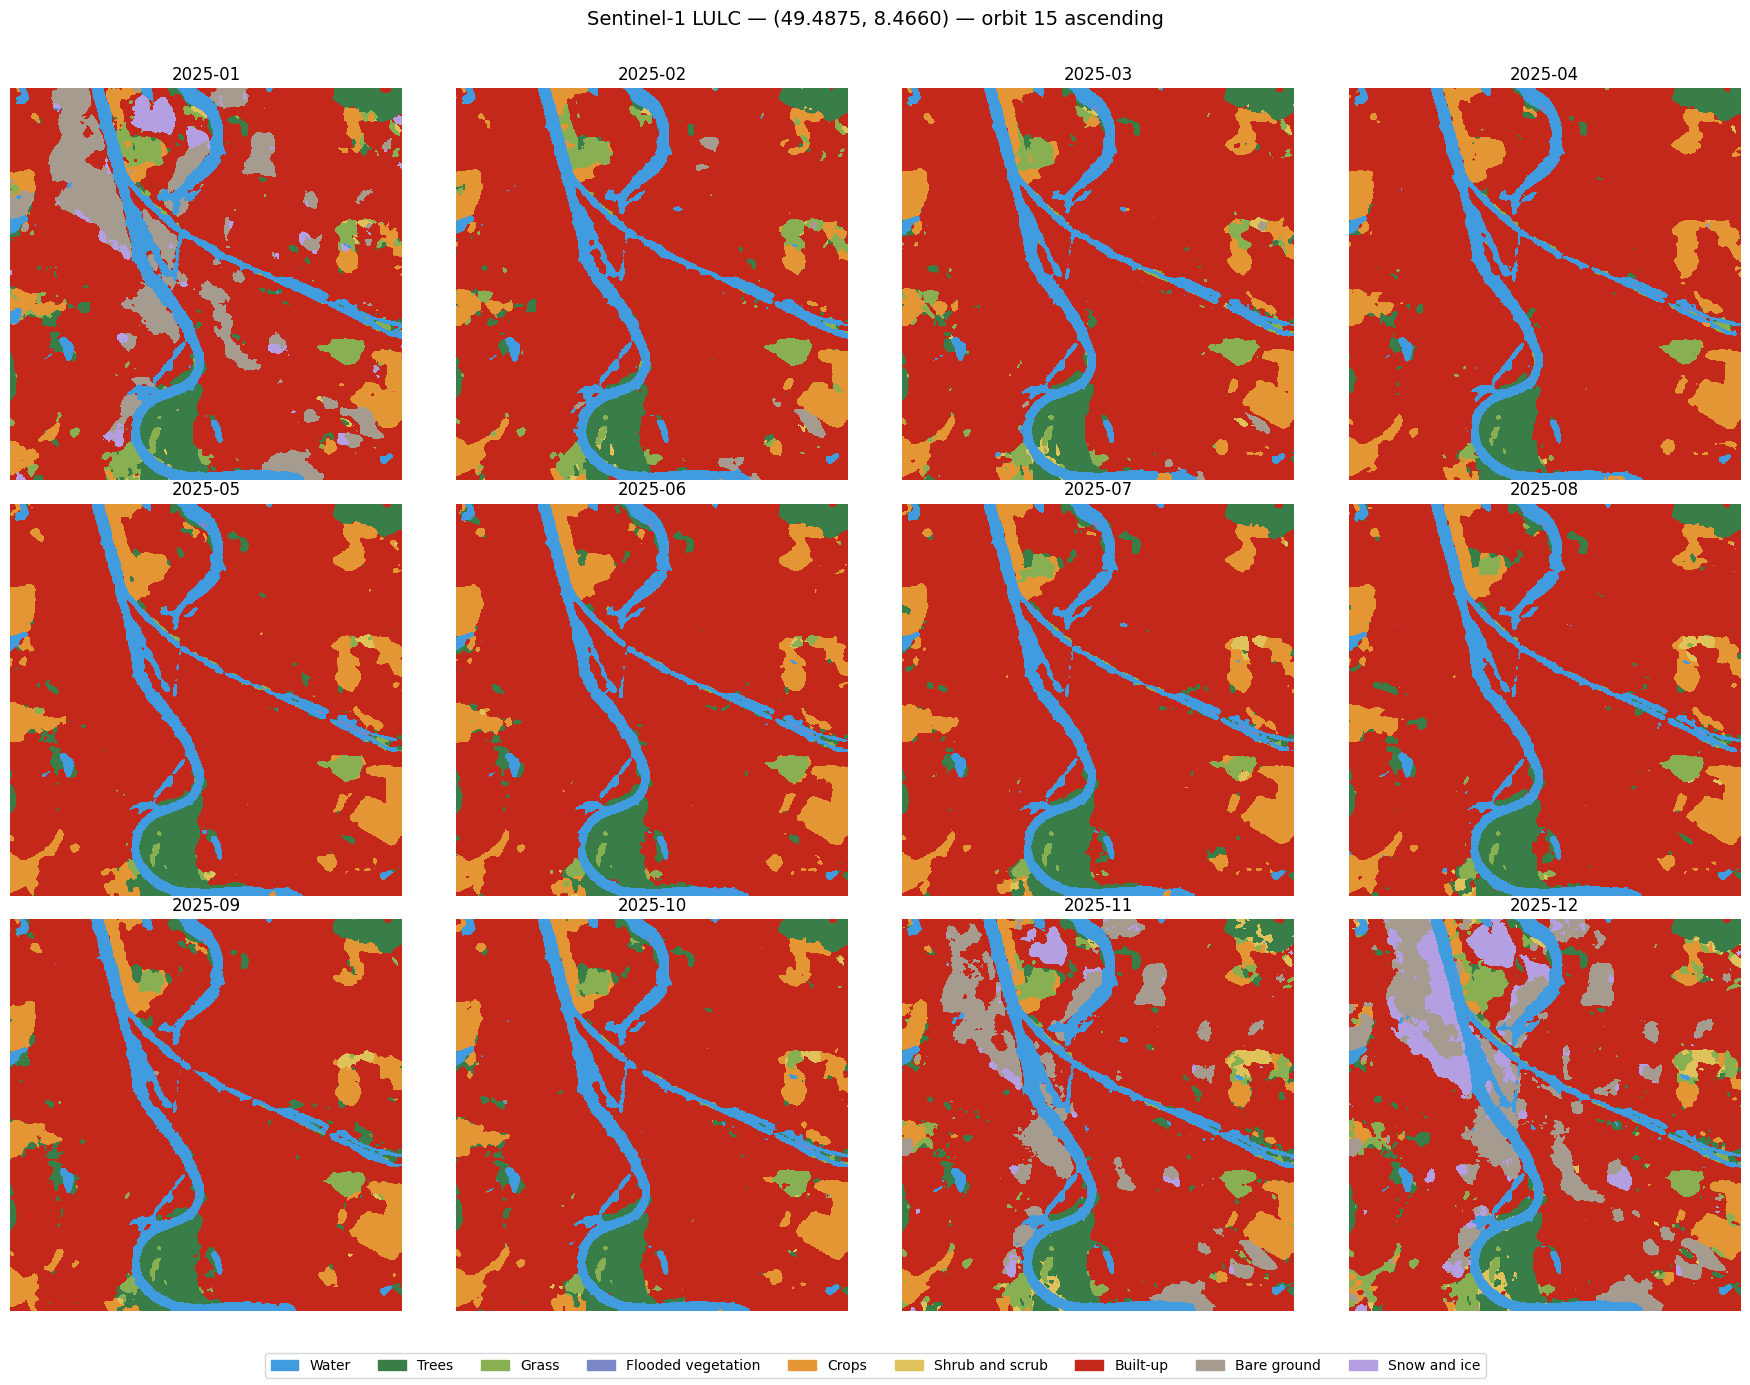

In [5]:
display(result["figures"]["maps"])

## 2. Percentage of the area covered by each class, per month

In [6]:
display(result["pct"].round(2))

,Water,Trees,Grass,Flooded vegetation,Crops,Shrub and scrub,Built-up,Bare ground,Snow and ice
month,,,,,,,,,
2025-01,9.01,5.10,3.27,0.00,4.62,0.21,64.04,11.70,2.04
2025-02,8.59,4.43,3.45,0.00,5.32,0.16,77.31,0.73,0.00
2025-03,7.97,4.58,2.79,0.01,6.70,0.32,77.34,0.28,0.00
2025-04,7.75,4.55,0.91,0.05,8.14,0.03,78.55,0.02,0.00
2025-05,7.52,5.24,0.94,0.09,8.88,0.15,77.20,0.00,0.00
2025-06,7.69,5.65,1.02,0.04,8.21,0.06,77.32,0.00,0.00
2025-07,7.78,5.72,1.18,0.04,7.56,0.35,77.37,0.00,0.00
2025-08,7.93,5.97,1.20,0.02,7.51,0.40,76.96,0.00,0.00
2025-09,7.89,6.12,1.13,0.01,6.91,0.27,77.66,0.01,0.00


## 3. Month-to-month change (percentage points)

In [7]:
display(result["mom"].round(2))

,Water,Trees,Grass,Flooded vegetation,Crops,Shrub and scrub,Built-up,Bare ground,Snow and ice
month,,,,,,,,,
2025-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-02,-0.42,-0.67,0.18,-0.00,0.70,-0.05,13.27,-10.97,-2.04
2025-03,-0.62,0.15,-0.66,0.01,1.38,0.16,0.03,-0.45,0.00
2025-04,-0.22,-0.02,-1.88,0.03,1.44,-0.29,1.21,-0.27,0.00
2025-05,-0.23,0.68,0.03,0.04,0.74,0.12,-1.35,-0.02,0.00
2025-06,0.18,0.42,0.08,-0.05,-0.67,-0.08,0.13,0.00,0.00
2025-07,0.09,0.07,0.16,0.00,-0.65,0.29,0.04,0.00,0.00
2025-08,0.15,0.25,0.03,-0.02,-0.05,0.05,-0.41,0.00,0.00
2025-09,-0.04,0.15,-0.08,-0.01,-0.60,-0.13,0.70,0.01,0.00


## 4. Total change from the first to the last month (percentage points)

,2025-01 → 2025-12 (pp)
Water,-0.43
Trees,0.45
Grass,1.03
Flooded vegetation,-0.00
Crops,-1.34
Shrub and scrub,0.66
Built-up,-4.13
Bare ground,0.30
Snow and ice,3.47


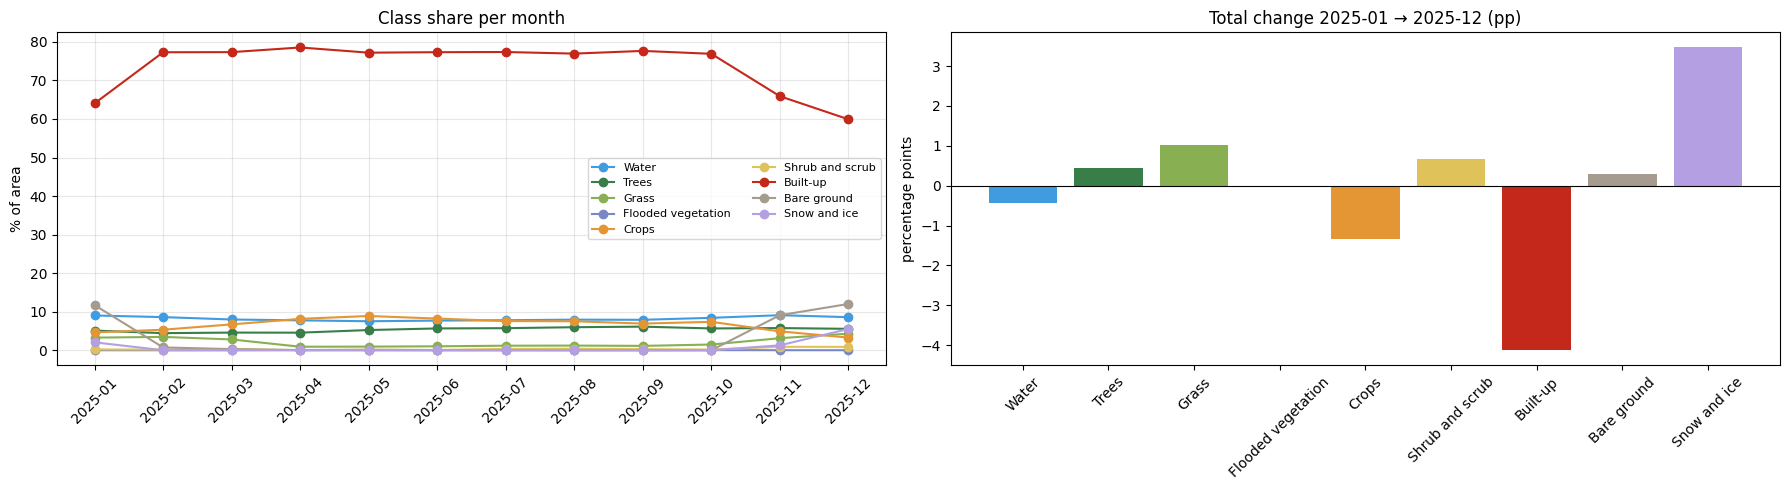

In [8]:
display(result["total"].round(2).to_frame())
display(result["figures"]["shares"])

## 5. Sanity check against an independent map (ESA WorldCover 2021, not used for training)
The prototype's most frequent class over the 12 months is compared with WorldCover, after mapping the
WorldCover classes to the 9 Dynamic World classes. Differences are expected: different year (2021),
different sensors (Sentinel-1 + Sentinel-2), different class definitions.

Pixel agreement with WorldCover: 69.2 %


,prototype_%,WorldCover_%,difference_pp,IoU
Water,8.26,6.33,1.93,0.73
Trees,5.25,26.14,-20.88,0.19
Grass,1.75,8.02,-6.27,0.15
Flooded vegetation,0.02,0.00,0.02,0.00
Crops,7.17,6.22,0.95,0.64
Shrub and scrub,0.16,0.00,0.16,0.00
Built-up,77.39,53.08,24.31,0.66
Bare ground,0.00,0.22,-0.22,0.00
Snow and ice,0.00,0.00,0.00,NaN


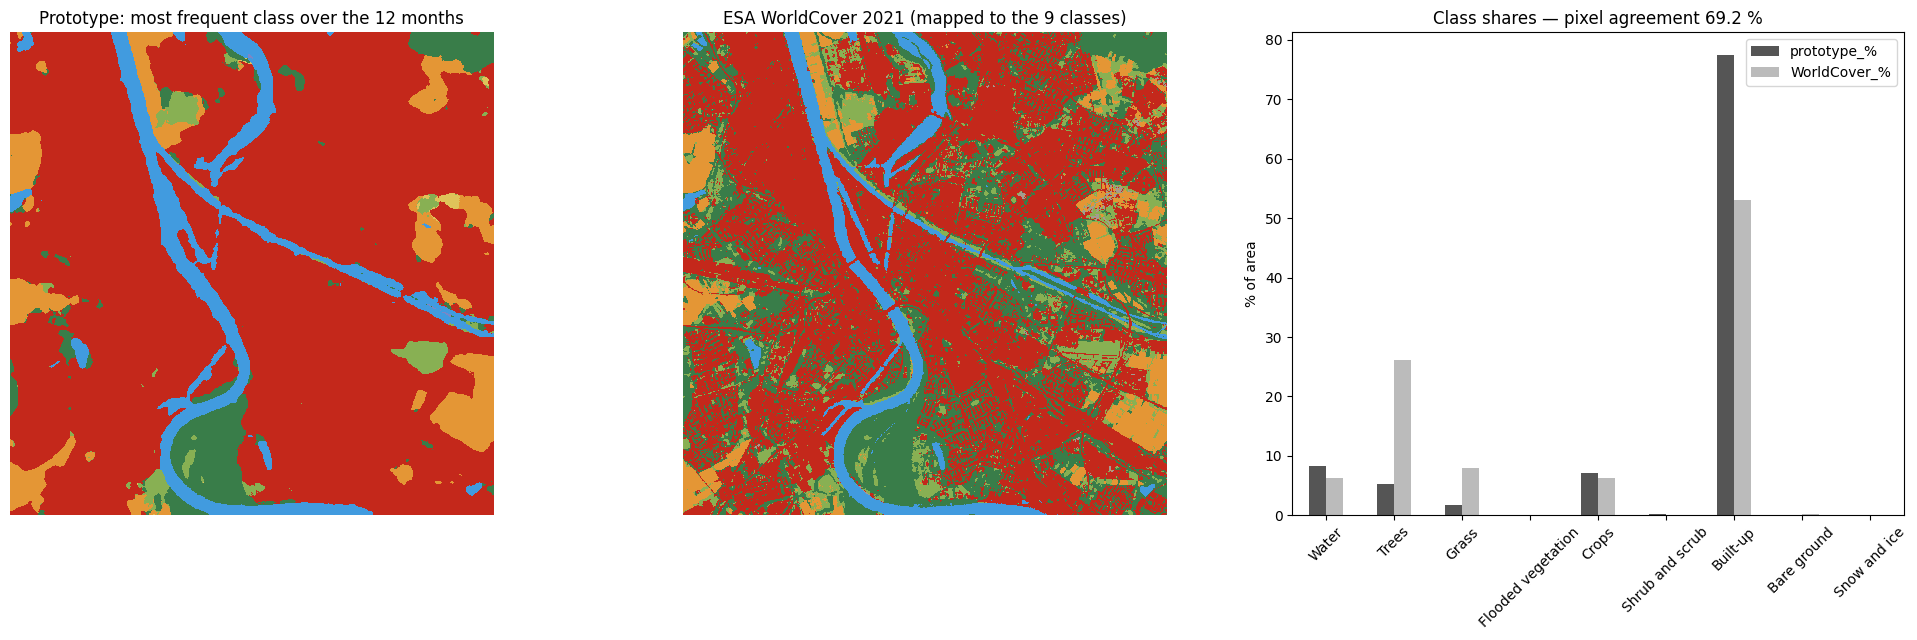

In [9]:
cmp = result["worldcover_cmp"]
print(f"Pixel agreement with WorldCover: {100 * cmp['agreement']:.1f} %")
display(cmp["table"].round(2))
display(result["figures"]["worldcover"])

In [10]:
print("Sentinel-1 relative orbit used:", result["orbit"], "(ascending)  | scenes per orbit:", result["orbit_histogram"])
print("Scenes per month:", dict(zip(result["labels"], result["n_images"])))
print("All outputs saved in:", result["out_dir"])

Sentinel-1 relative orbit used: 15 (ascending)  | scenes per orbit: {15: 53}
Scenes per month: {'2025-01': 3, '2025-02': 2, '2025-03': 3, '2025-04': 2, '2025-05': 5, '2025-06': 5, '2025-07': 5, '2025-08': 5, '2025-09': 7, '2025-10': 5, '2025-11': 5, '2025-12': 6}
All outputs saved in: results/lat49.4875_lon8.4660_2025-01


## 6. Change figures for the report
Heat map of the month-to-month change, class share per month and total change. Computed from `result` above and
saved to `outputs/figures/` with the city name in the file name.

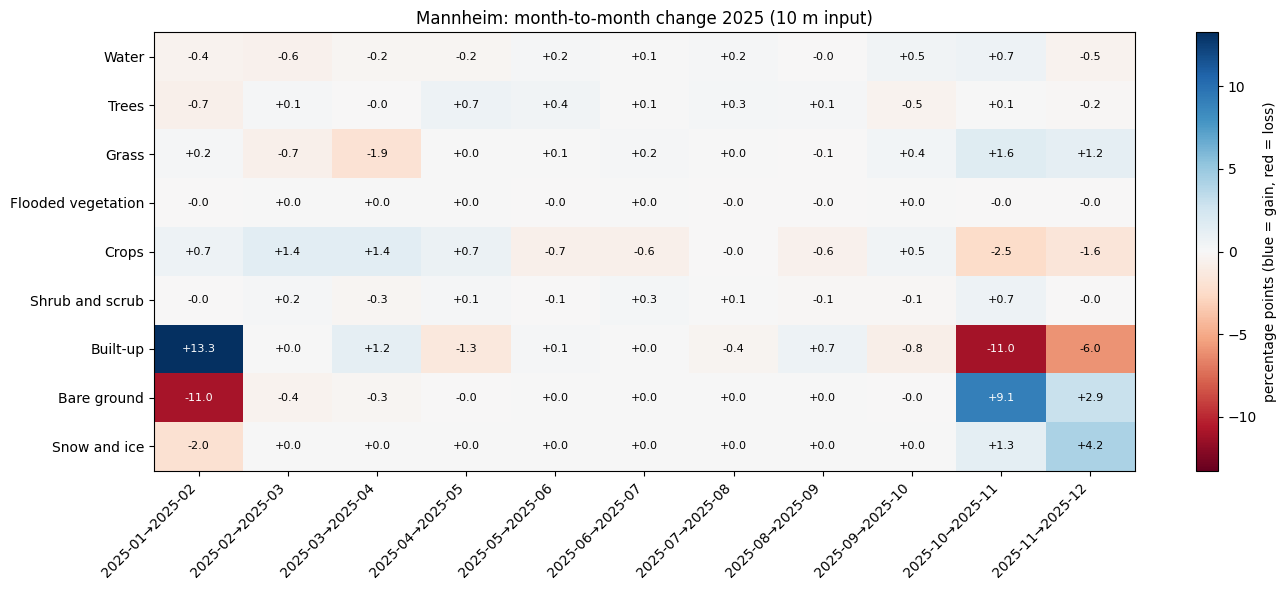

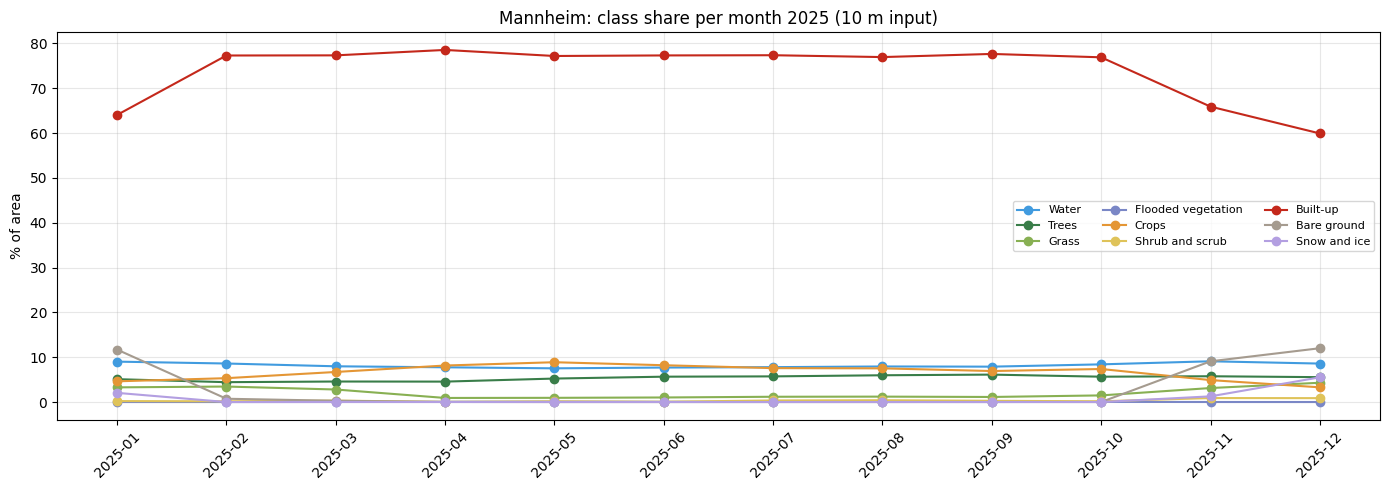

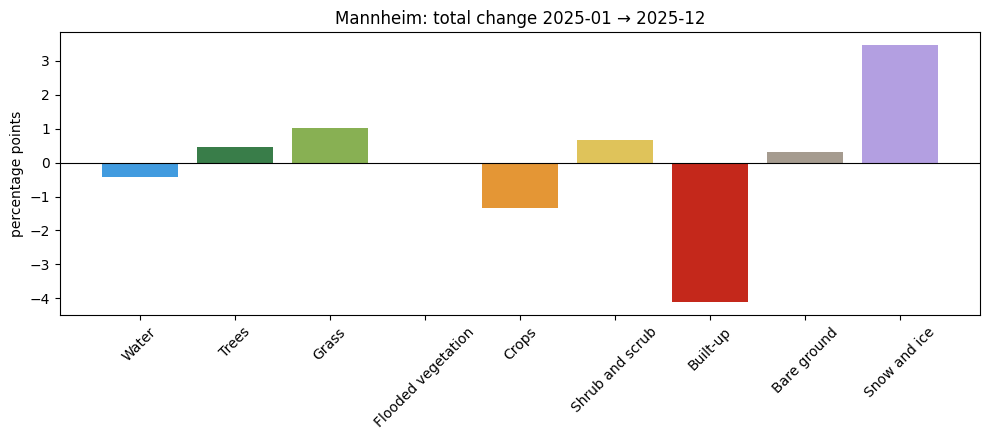

Mannheim: largest month-to-month change = Built-up in 2025-02: +13.27 pp


In [11]:
CLASSES, PALETTE = list(P.CLASS_NAMES), list(P.PALETTE)
TAG = CITY if INPUT_RES == 10 else f"{CITY}_40m"
pct = result["pct"][CLASSES]
mom = result["mom"][CLASSES].iloc[1:]
tot = result["total"].loc[CLASSES]

# 6a. month-to-month change heat map
vmax = np.nanmax(np.abs(mom.values))
fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(mom.T.values, cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(mom.index)))
ax.set_xticklabels([f"{a}→{b}" for a, b in zip(pct.index[:-1], mom.index)], rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(mom.index)):
        v = mom.T.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > vmax * 0.5 else "black")
fig.colorbar(im, ax=ax, label="percentage points (blue = gain, red = loss)")
ax.set_title(f"{CITY}: month-to-month change 2025 ({INPUT_RES} m input)")
plt.tight_layout(); plt.savefig(f"{FIG}/{TAG}_month_to_month_heatmap.png", dpi=150); plt.show()

# 6b. class share per month
fig, ax = plt.subplots(figsize=(14, 5))
for c, col in zip(CLASSES, PALETTE):
    ax.plot(pct.index, pct[c], "-o", color=col, label=c)
ax.set_ylabel("% of area"); ax.set_title(f"{CITY}: class share per month 2025 ({INPUT_RES} m input)")
ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=3); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{FIG}/{TAG}_class_share.png", dpi=150); plt.show()

# 6c. total change first -> last month
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(CLASSES, tot.values, color=PALETTE); ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("percentage points"); ax.tick_params(axis="x", rotation=45)
ax.set_title(f"{CITY}: total change {result['labels'][0]} → {result['labels'][-1]}")
plt.tight_layout(); plt.savefig(f"{FIG}/{TAG}_total_change.png", dpi=150); plt.show()

s = mom.abs().stack(); (mo, cl) = s.idxmax()
print(f"{CITY}: largest month-to-month change = {cl} in {mo}: {mom.loc[mo, cl]:+.2f} pp")

## 7. Month-by-month change maps
For each pair of consecutive months: both maps, the pixels that changed class (coloured by their new class) and the
change of each class share. A summary table follows at the end.

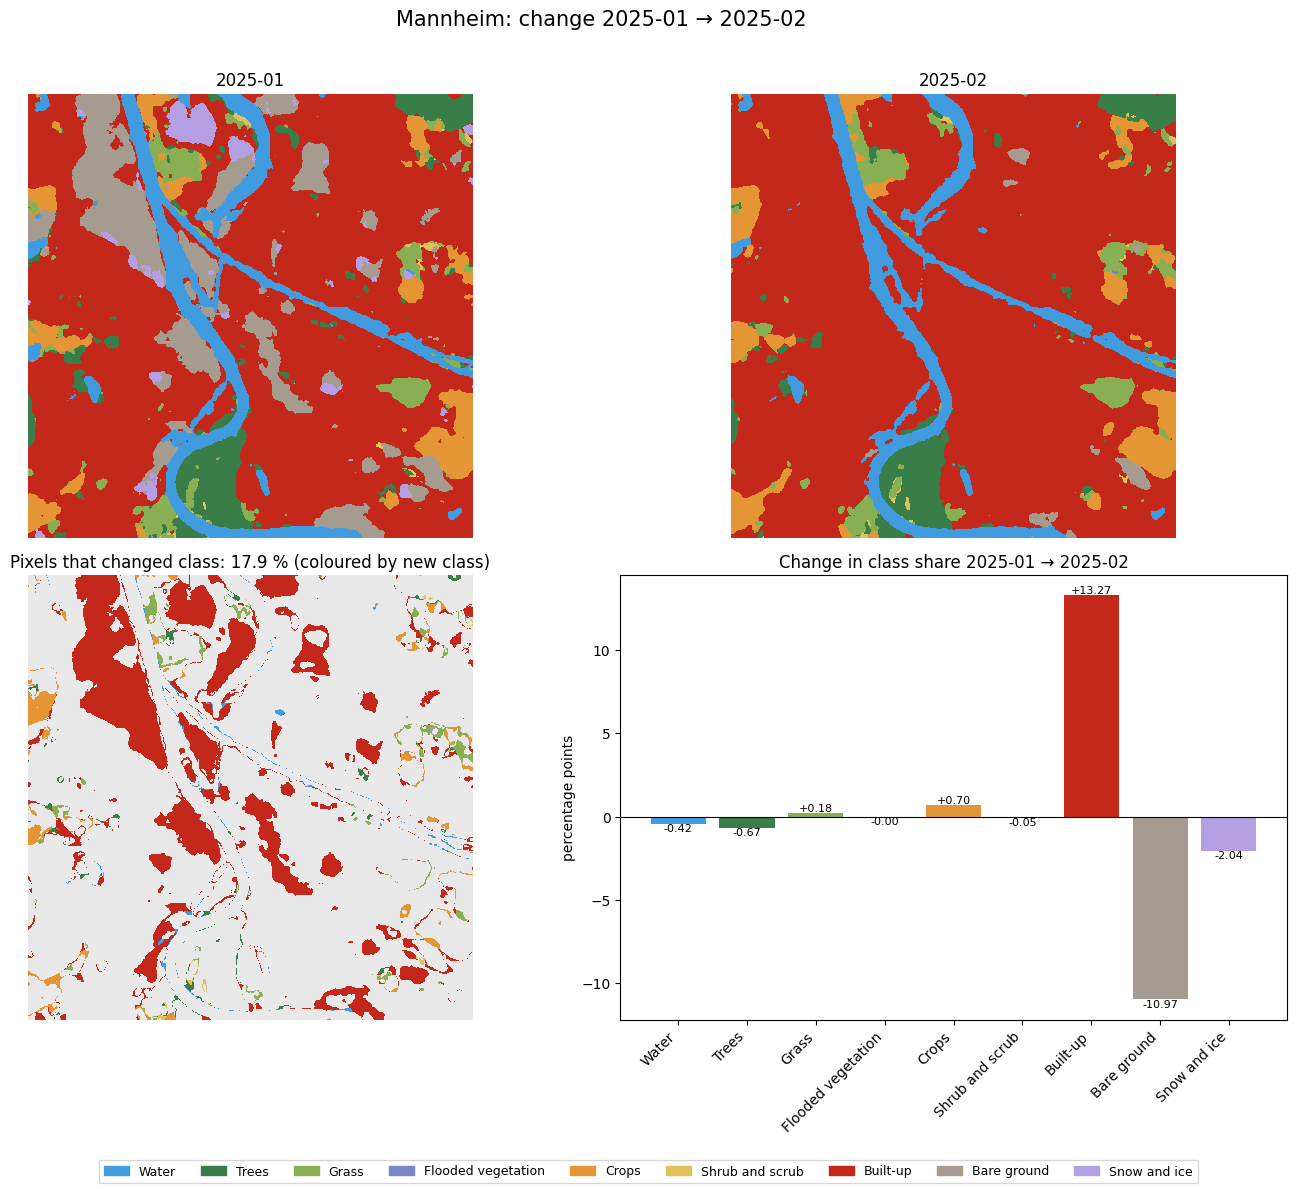

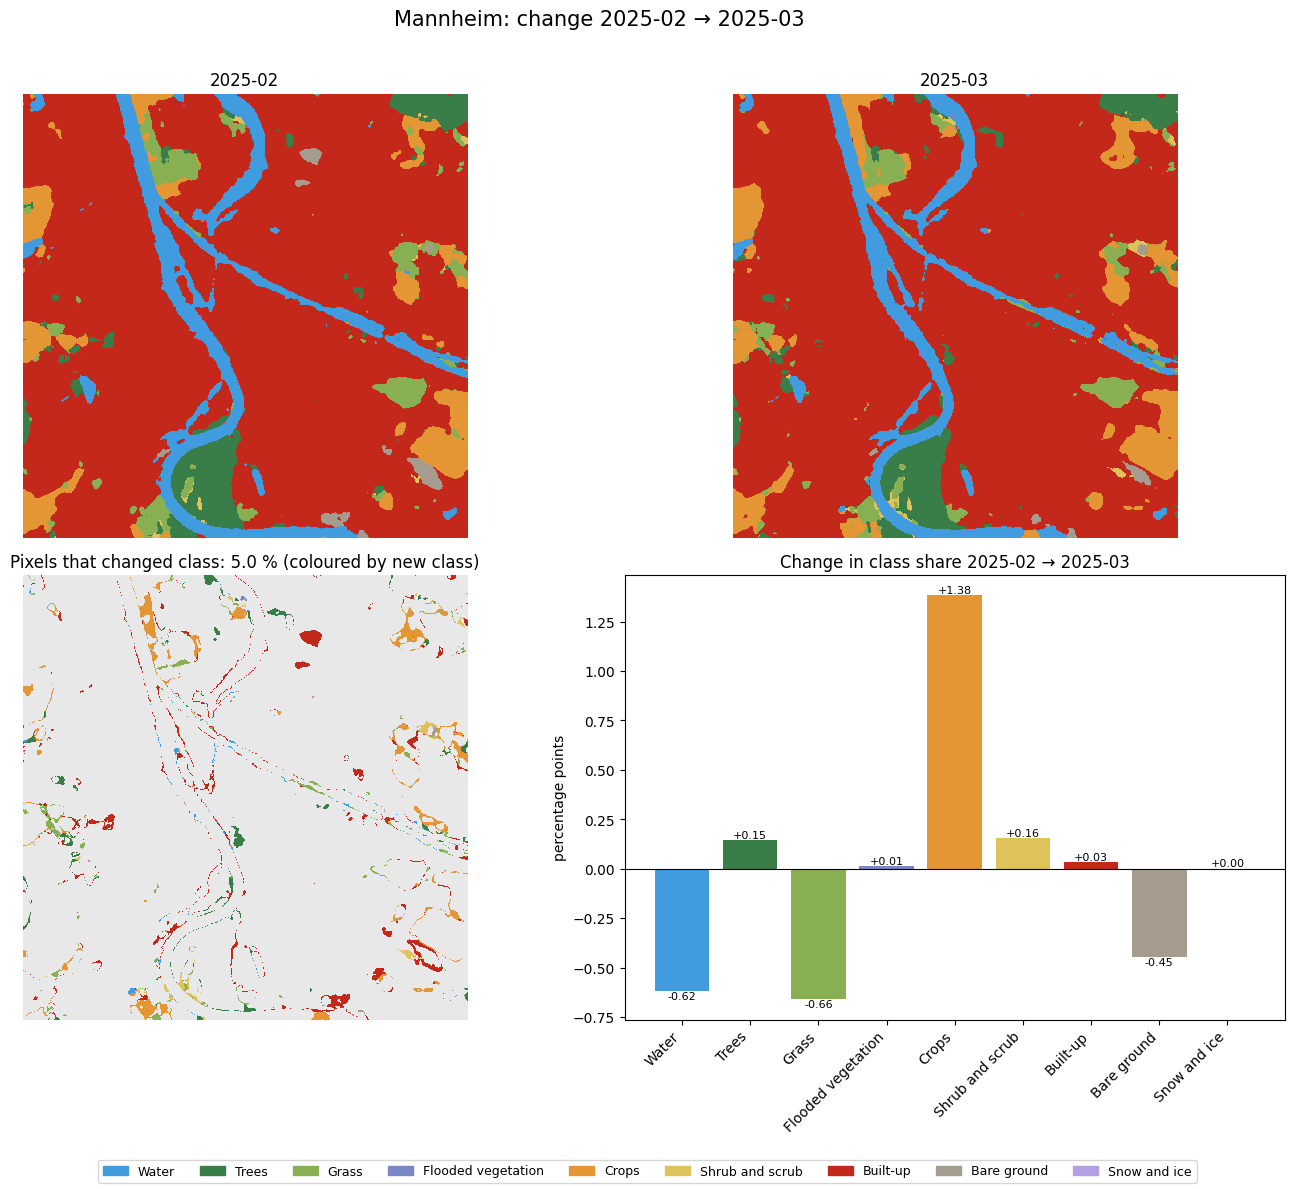

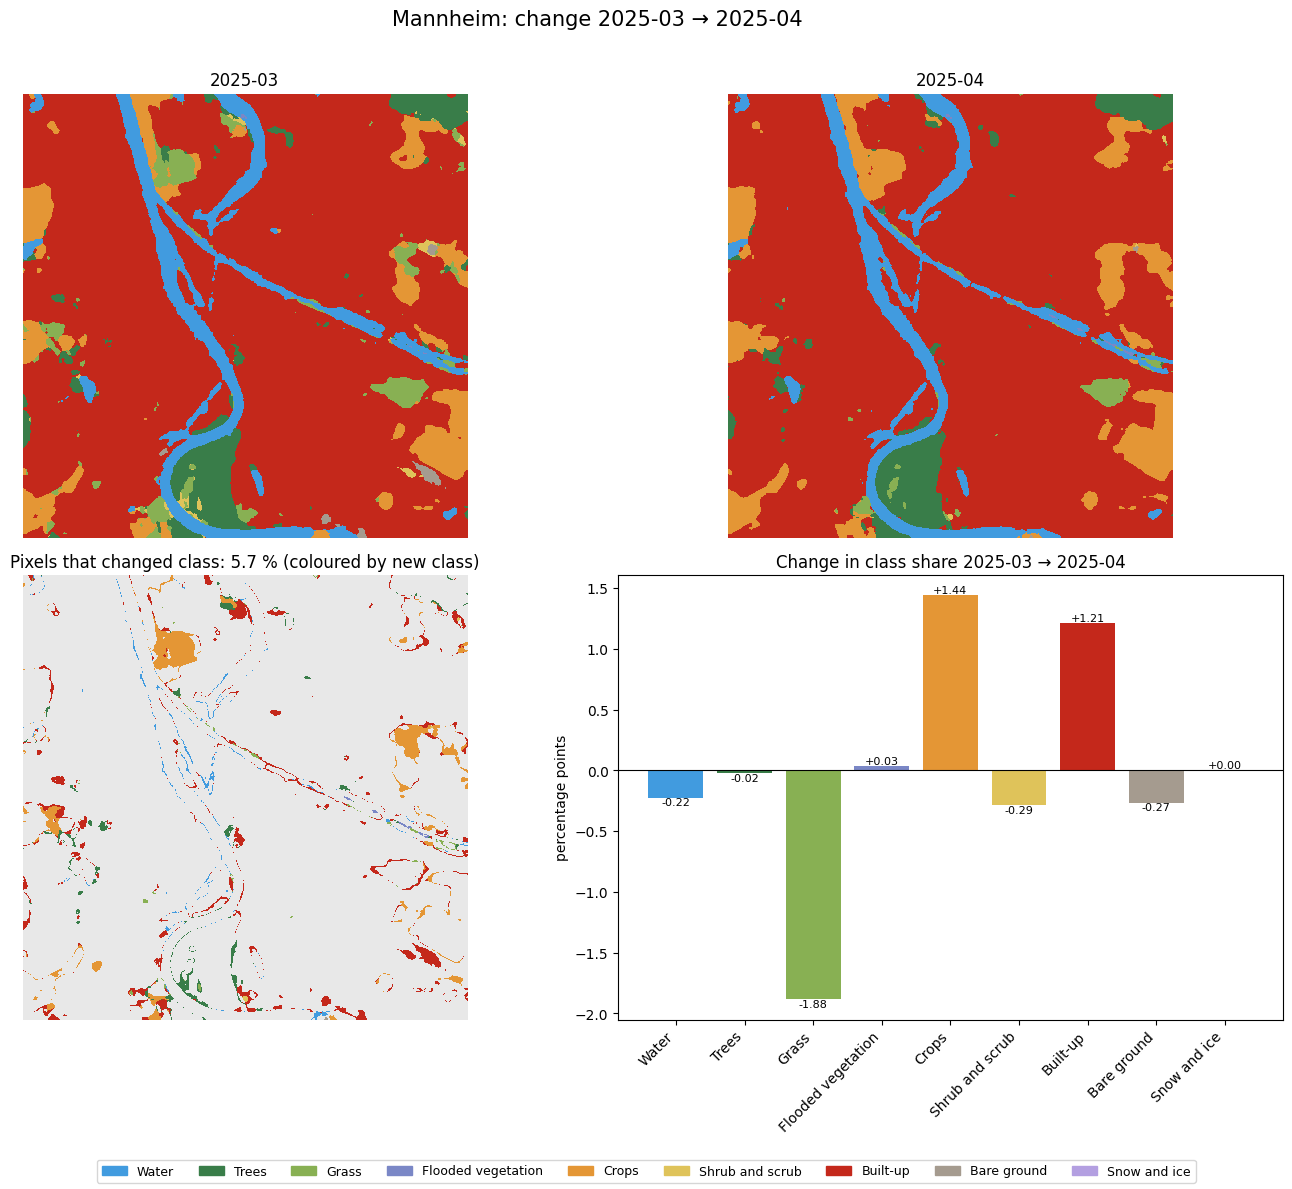

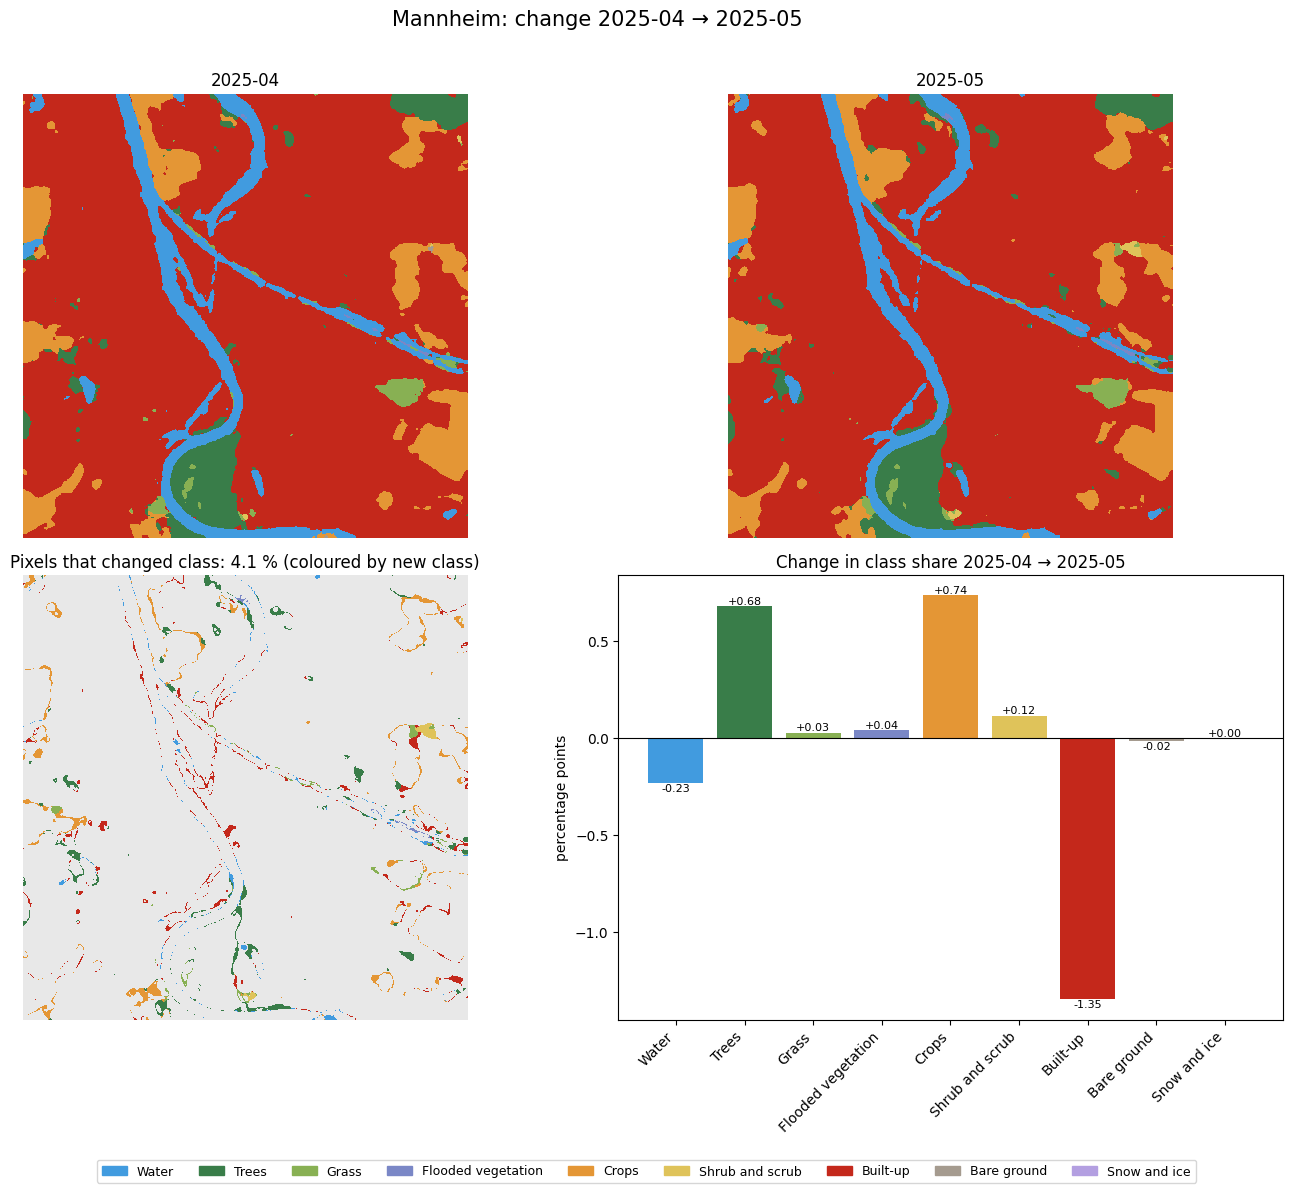

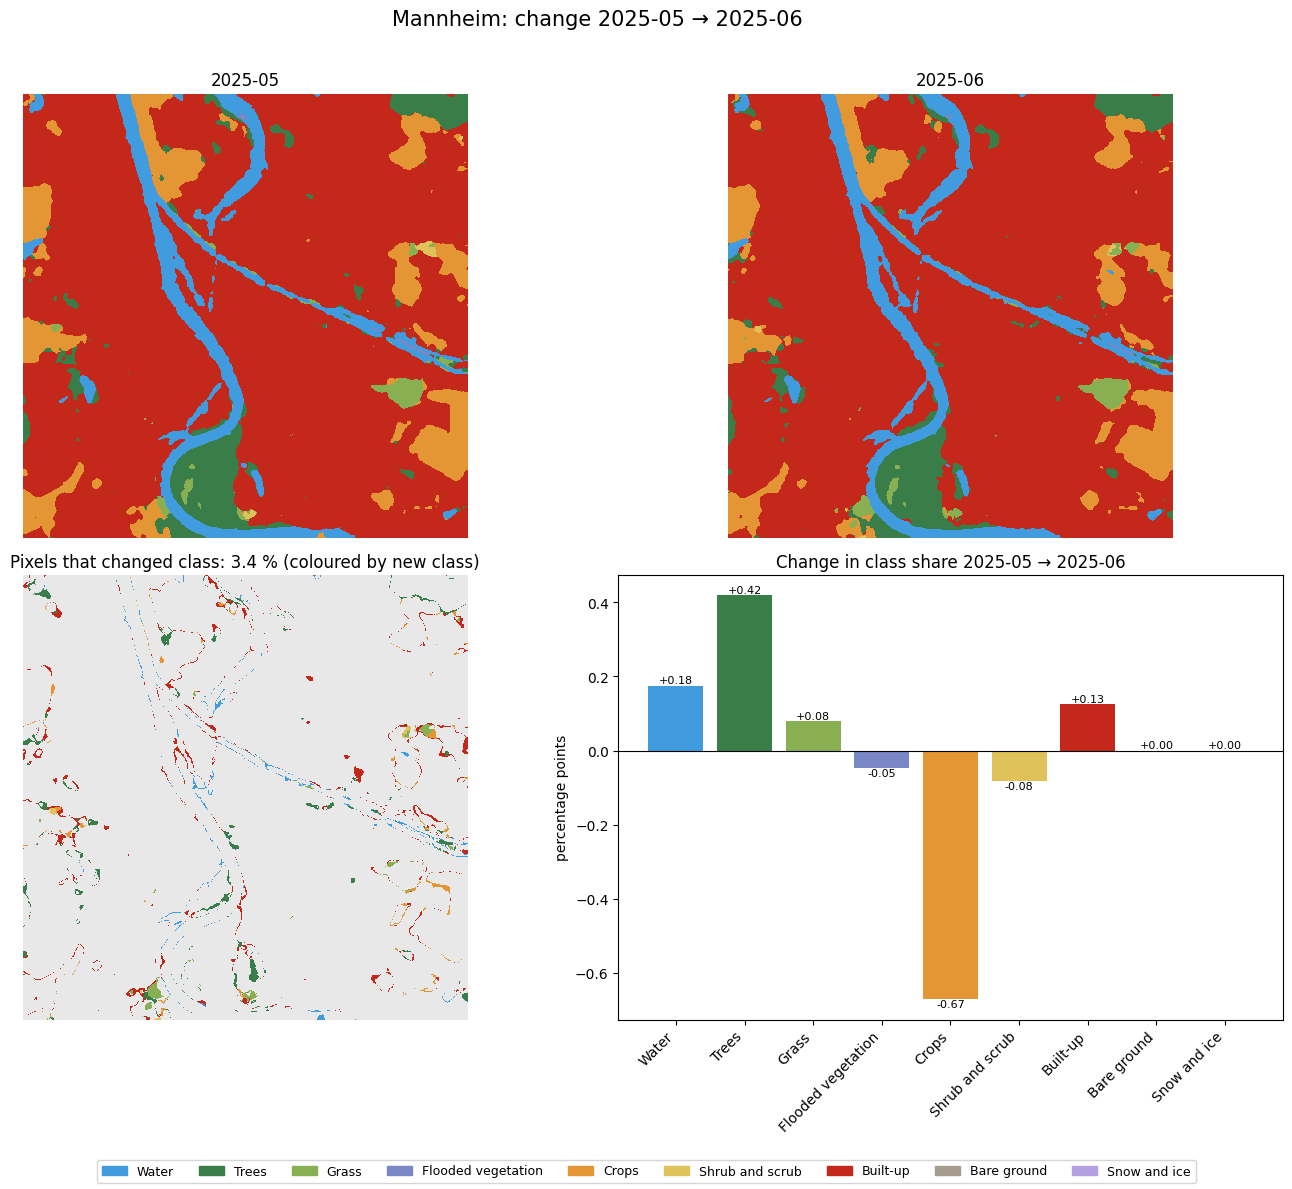

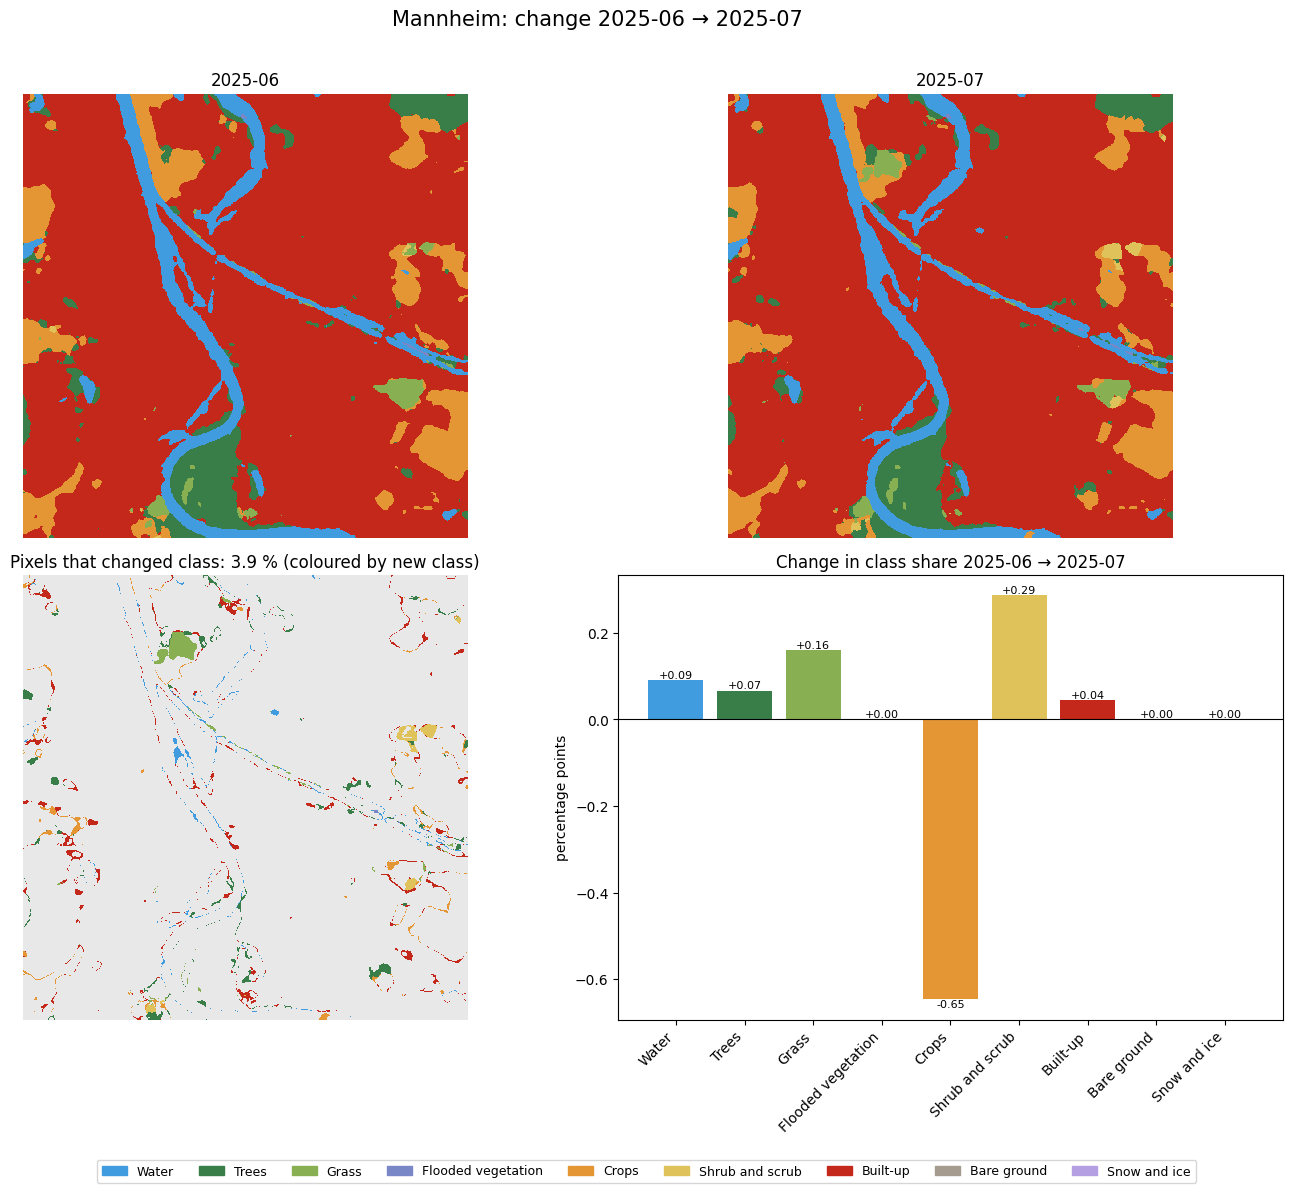

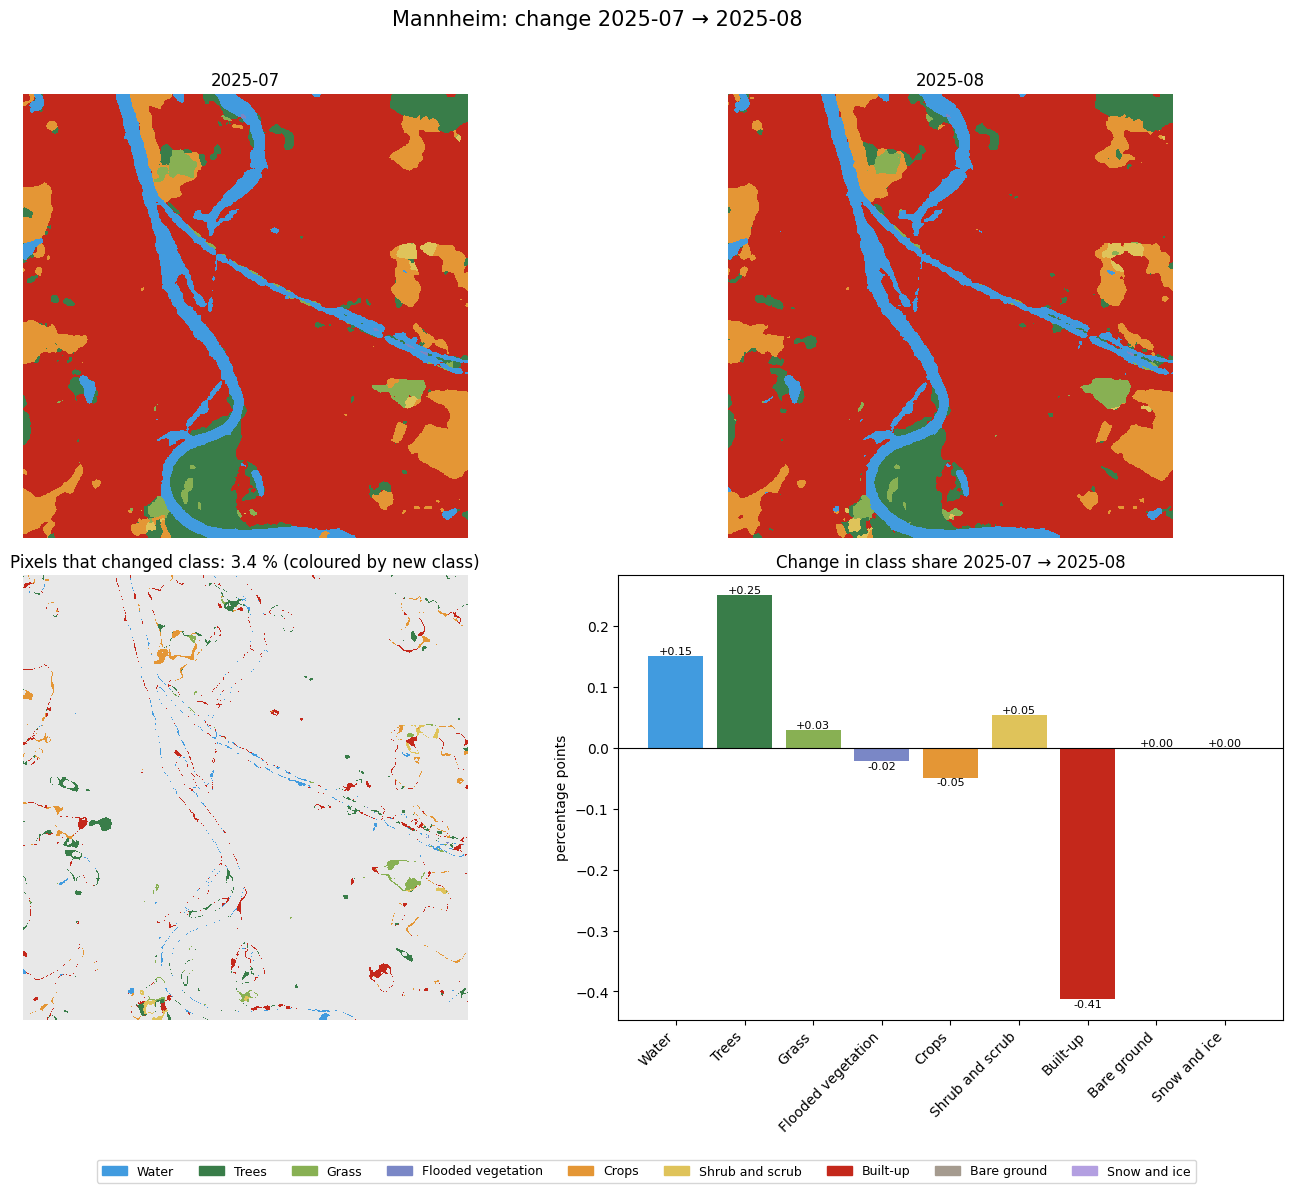

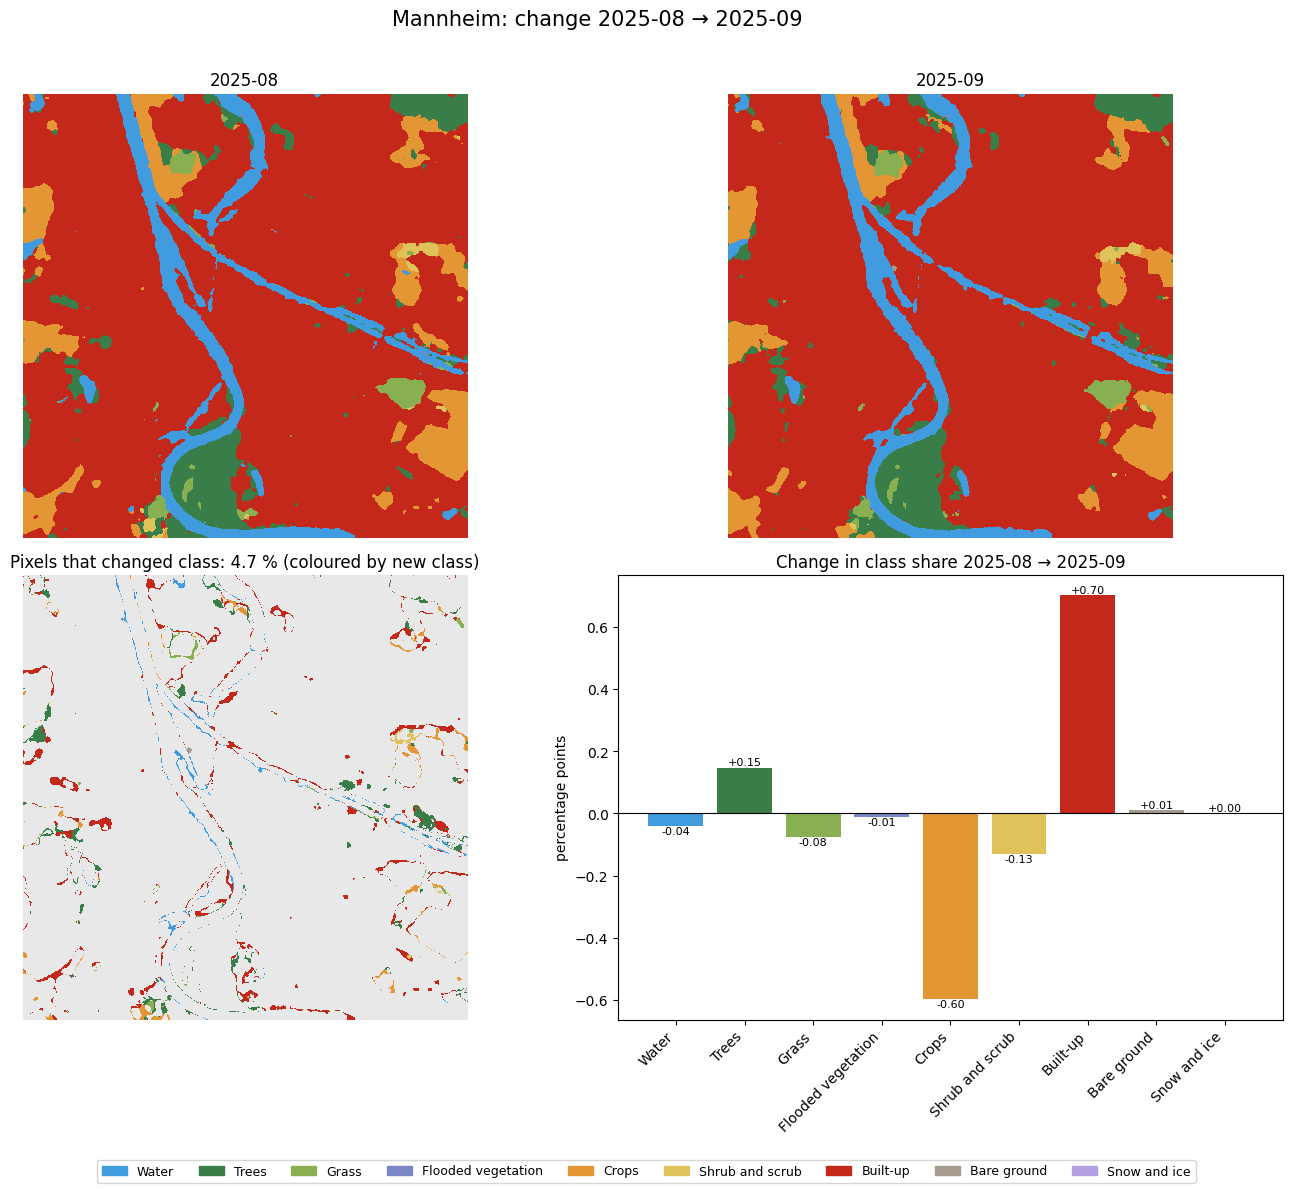

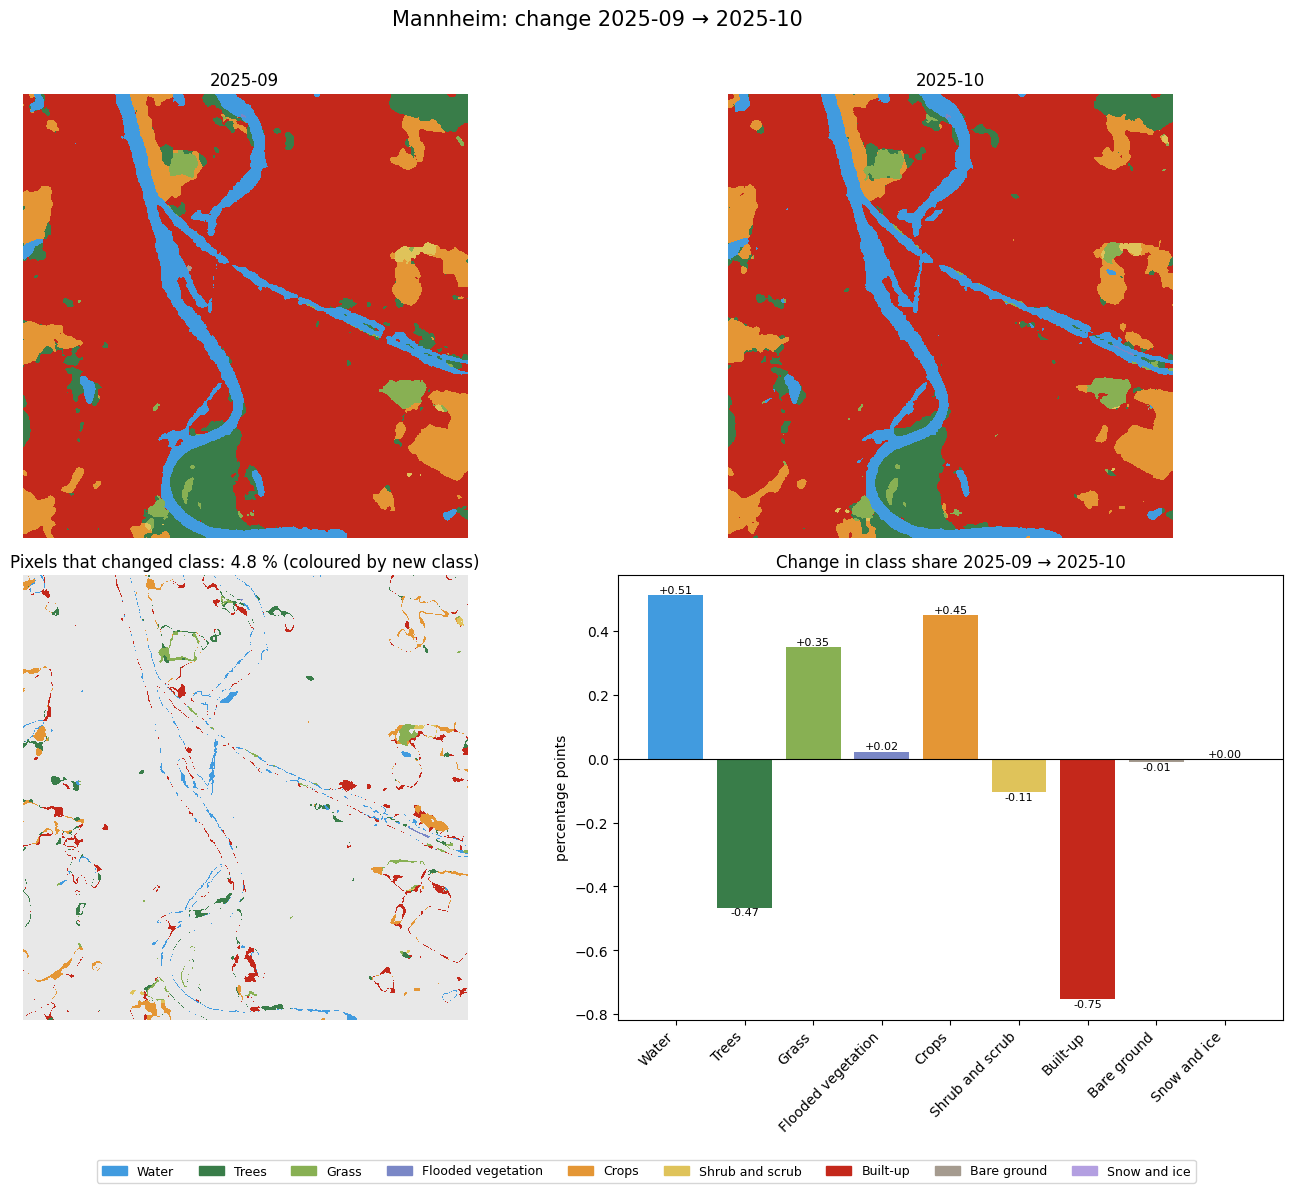

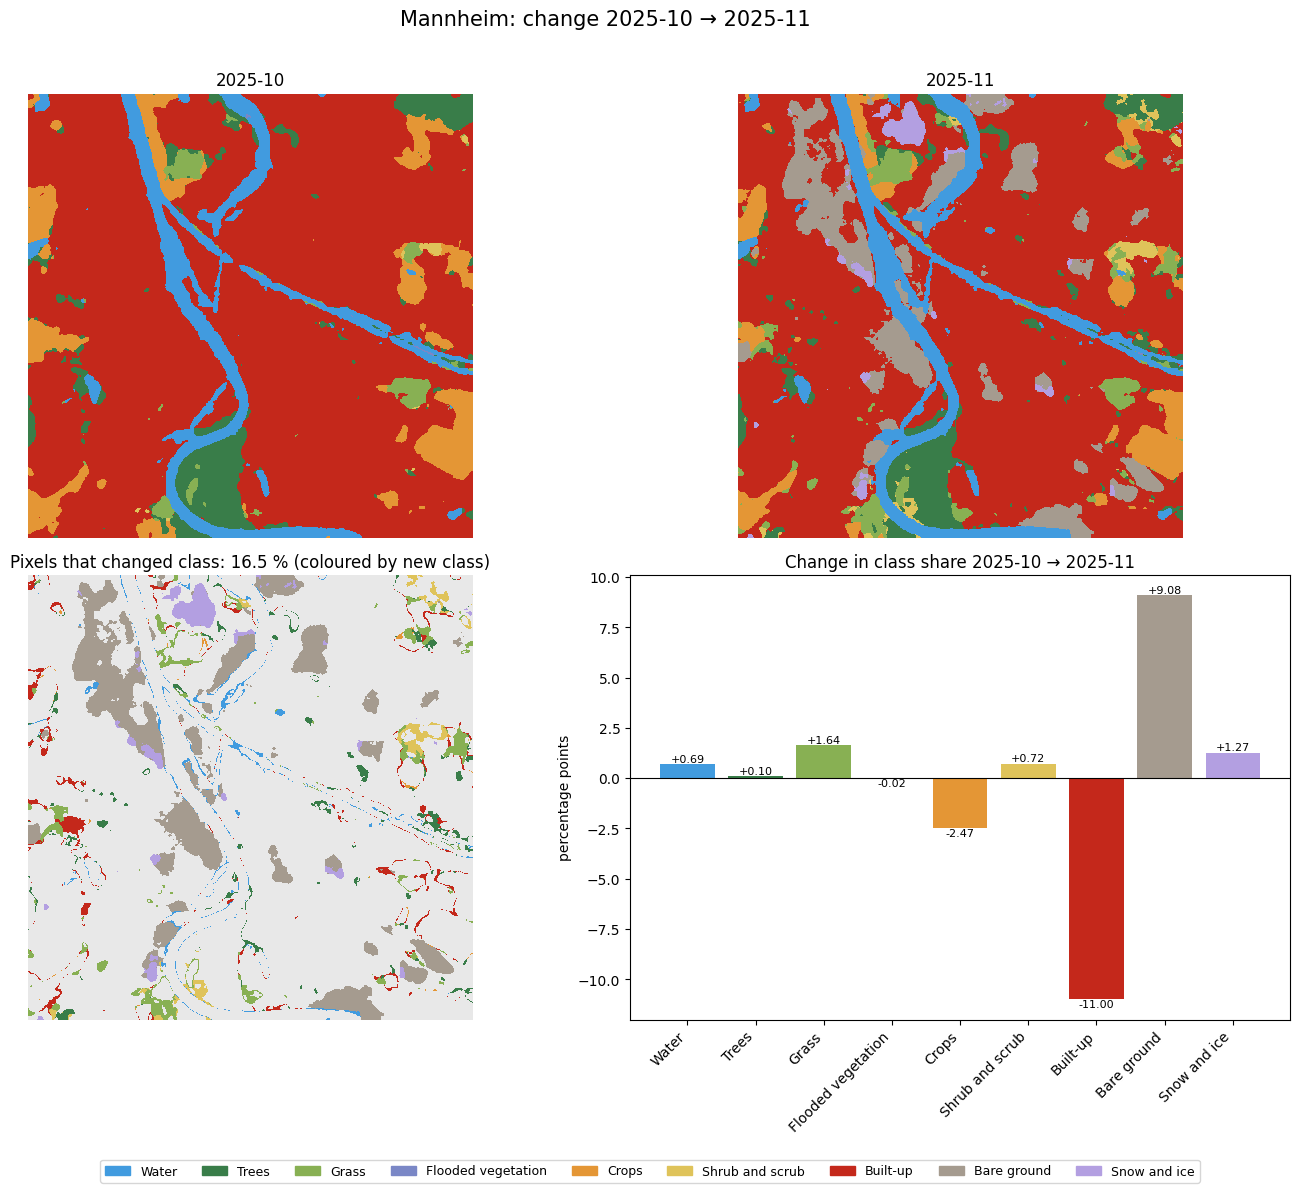

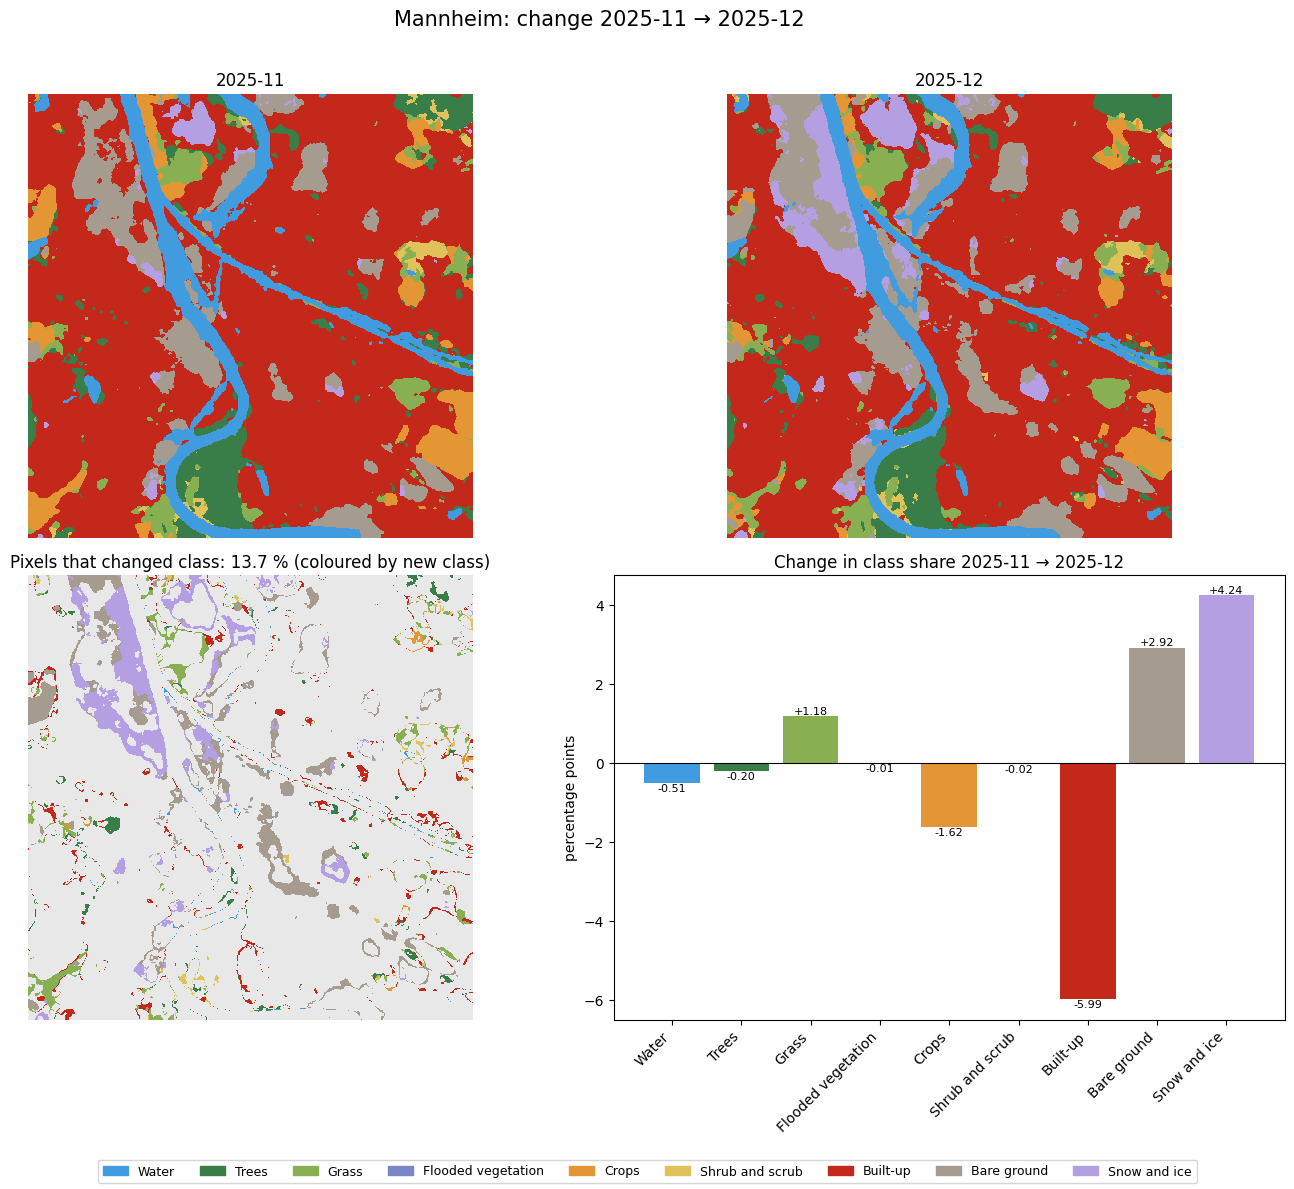

,pixels_changed_%,net_change_pp,largest
change,,,
2025-01 → 2025-02,17.91,14.15,Built-up +13.27 pp
2025-02 → 2025-03,5.05,1.73,Crops +1.38 pp
2025-03 → 2025-04,5.71,2.68,Grass -1.88 pp
2025-04 → 2025-05,4.09,1.60,Built-up -1.35 pp
2025-05 → 2025-06,3.42,0.80,Crops -0.67 pp
2025-06 → 2025-07,3.93,0.65,Crops -0.65 pp
2025-07 → 2025-08,3.36,0.48,Built-up -0.41 pp
2025-08 → 2025-09,4.65,0.86,Built-up +0.70 pp
2025-09 → 2025-10,4.79,1.33,Built-up -0.75 pp


Figures and summary saved in: /home/jovyan/vault/heidelberg_lulc_2025/outputs/figures/Mannheim_monthly_changes


In [12]:
CMAP, NORM = ListedColormap(PALETTE), BoundaryNorm(np.arange(-0.5, 9.5), 9)
maps, labels = result["maps"], result["labels"]
out = f"{FIG}/{TAG}_monthly_changes"; os.makedirs(out, exist_ok=True)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in PALETTE]

def show_map(ax, a, title):
    s = a.astype(float); s[a == P.NODATA] = np.nan
    ax.imshow(s, cmap=CMAP, norm=NORM, interpolation="nearest"); ax.set_title(title); ax.axis("off")

rows = []
for k in range(1, len(maps)):
    a, b = maps[k - 1], maps[k]
    valid = (a != P.NODATA) & (b != P.NODATA)
    if not valid.any():
        continue
    changed = (a != b) & valid
    d = pct.iloc[k] - pct.iloc[k - 1]
    rows.append({"change": f"{labels[k-1]} → {labels[k]}",
                 "pixels_changed_%": 100 * changed.sum() / valid.sum(),
                 "net_change_pp": d.abs().sum() / 2,
                 "largest": f"{d.abs().idxmax()} {d[d.abs().idxmax()]:+.2f} pp"})
    fig, axs = plt.subplots(2, 2, figsize=(14, 12))
    show_map(axs[0, 0], a, labels[k - 1]); show_map(axs[0, 1], b, labels[k])
    cm = np.full(a.shape, np.nan); cm[changed] = b[changed]
    axs[1, 0].imshow(np.where(valid, 0.5, np.nan), cmap="Greys", vmin=0, vmax=3)
    axs[1, 0].imshow(cm, cmap=CMAP, norm=NORM, interpolation="nearest")
    axs[1, 0].set_title(f"Pixels that changed class: {rows[-1]['pixels_changed_%']:.1f} % (coloured by new class)")
    axs[1, 0].axis("off")
    bars = axs[1, 1].bar(range(9), d.values, color=PALETTE); axs[1, 1].axhline(0, color="k", lw=0.8)
    axs[1, 1].set_xticks(range(9)); axs[1, 1].set_xticklabels(CLASSES, rotation=45, ha="right")
    axs[1, 1].set_ylabel("percentage points"); axs[1, 1].set_title(f"Change in class share {labels[k-1]} → {labels[k]}")
    for r, v in zip(bars, d.values):
        axs[1, 1].text(r.get_x() + r.get_width() / 2, v, f"{v:+.2f}", ha="center",
                       va="bottom" if v >= 0 else "top", fontsize=8)
    fig.legend(handles, CLASSES, loc="lower center", ncol=9, fontsize=9)
    fig.suptitle(f"{CITY}: change {labels[k-1]} → {labels[k]}", fontsize=15)
    plt.tight_layout(rect=(0, 0.03, 1, 0.97))
    plt.savefig(f"{out}/{TAG}_change_{labels[k-1]}_to_{labels[k]}.png", dpi=110); plt.show()

summary = pd.DataFrame(rows).set_index("change")
summary.round(2).to_csv(f"{out}/{TAG}_monthly_change_summary.csv")
display(summary.round(2))
print("Figures and summary saved in:", out)